# Chapter 50: Money, Monetary Standards, Velocity, and Inflation

This notebook reruns four worked examples from the chapter: the quantity theory with moving velocity and output, deflation and the real burden of debt, the Baumol-Tobin rule for cash transfers, and the inflation tax on existing money. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def quantity_price(M, V, Y):
    """Price level from the equation of exchange, P = M V / Y.

    quantity-theory-of-money (chapter 50): 1,000 x 4 / 2,000 = 2; 1,250 x 4 / 2,000 = 2.5;
    1,250 x 3.2 / 2,000 = 2; 1,250 x 4 / 2,200 = 2.2727.
    deflation-and-monetary-contraction: 500 x 4 / 1,000 = 2; 450 x 3.8 / 980 = 1.7449.
    """
    return M * V / Y


def real_value(nominal, P):
    """Real value of a nominal amount at price index P: nominal / P.

    deflation-and-monetary-contraction (chapter 50): 200 / 2 = 100; 200 / 1.7449 = 114.62.
    """
    return nominal / P


def inflation_tax(holdings, P0, P1):
    """Inflation tax on existing money holdings when the index moves from P0 to P1.

    seigniorage-inflation-tax (chapter 50): holdings 10,000, P0 = 1, P1 = 1.10. Returns
    inflation (0.10), exact erosion holdings/P0 - holdings/P1 = 909.09, the same as
    inflation x final real balances, the beginning-balance approximation inflation x
    holdings/P0 = 1,000 and its error 90.91.
    """
    pi = P1 / P0 - 1.0
    real0, real1 = holdings / P0, holdings / P1
    exact = real0 - real1
    approx = pi * real0
    return {"inflation": pi, "real_before": real0, "real_after": real1, "exact": exact,
            "via_final": pi * real1, "approx": approx, "error": approx - exact}


def baumol_tobin(T, b, i):
    """Optimal cash withdrawal sqrt(2 b T / i) and the number of trips T / that amount."""
    c = math.sqrt(2.0 * b * T / i)
    return {"withdrawal": c, "trips": T / c, "average_cash": c / 2.0}


plt.rcParams.update(HOUSE_RC)


macro = SimpleNamespace(quantity_price=quantity_price, real_value=real_value, inflation_tax=inflation_tax)


choice = SimpleNamespace(baumol_tobin=baumol_tobin)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'quantity-theory-of-money': {'M0': 1000,
                              'V0': 4,
                              'Y0': 2000,
                              'M1': 1250,
                              'P0': 2,
                              'P1': 2.5,
                              'V_low': 3.2,
                              'P1_V_low': 2,
                              'Y_high': 2200,
                              'P1_Y_high': 2.2727,
                              'change_Y_high_pct': 13.64},
 'deflation-and-monetary-contraction': {'M0': 500,
                                        'V0': 4,
                                        'Y0': 1000,
                                        'M1': 450,
                                        'V1': 3.8,
                                        'Y1': 980,
                                        'debt': 200,
                                        'P0': 2,
                                        'P1': 1.7449,
                                        'change_pct': -12.76,
                                        'real_debt_0': 100,
                                        'real_debt_1': 114.62,
                                        'M_star': 515.79,
                                        'extra': 65.79},
 'baumol-tobin-transactions-demand-for-money': {'T': 24000,
                                                'b': 6,
                                                'i': 0.04,
                                                'n_star': 8.944,
                                                'avg_9': 1333.33,
                                                'C9': 107.33,
                                                'C8': 108,
                                                'C10': 108,
                                                'i_2': 0.09,
                                                'n_star_2': 13.416,
                                                'M_star_2': 894.43},
 'seigniorage-inflation-tax': {'holdings': 10000,
                               'P0': 1,
                               'issue': 1000,
                               'P1': 1.1,
                               'exact': 909.09,
                               'real_after': 9090.91,
                               'approx': 1000,
                               'error': 90.91,
                               's': 909.09},
 'constructed': {'quantity-theory-of-money': {'M1': [1000, 1500]},
                 'deflation-and-monetary-contraction': {'M1': [475, 500], 'V1': [3.6, 4.0, 4.2]},
                 'baumol-tobin-transactions-demand-for-money': {'i': [0.02], 'b': [3, 12]},
                 'seigniorage-inflation-tax': {'issue': [500, 2000], 'holdings': [5000, 20000]}}}


def change_word(x, digits=2):
    """'rises 25.00 percent', 'falls 12.76 percent' or 'is unchanged' for a fractional change."""
    shown = num(100 * abs(x), digits)
    if float(shown.replace(",", "")) == 0:
        return "is unchanged"
    return f"{'rises' if x > 0 else 'falls'} {shown} percent"


def quantity_picture(m1=1250, v1=4.0, y1=2000):
    M1, V1, Y1 = m1, v1, y1
    b = BV["quantity-theory-of-money"]
    M0, V0, Y0 = b["M0"], b["V0"], b["Y0"]
    p0 = macro.quantity_price(M0, V0, Y0)
    p1 = macro.quantity_price(M1, V1, Y1)
    change = p1 / p0 - 1
    fig, (ax1, ax2) = new_figure(ncols=2)
    xs = np.arange(2)
    w = 0.36
    spend = [M0 * V0, M1 * V1]
    out = [Y0, Y1]
    ax1.bar(xs - w / 2, spend, width=w, color=PALETTE["navy"], label="Nominal spending MV")
    ax1.bar(xs + w / 2, out, width=w, color=PALETTE["gold"], label="Real output Y")
    for x, s, y in zip(xs, spend, out):
        label(ax1, x - w / 2, s, num(s, 0), dx=0, dy=3, ha="center")
        label(ax1, x + w / 2, y, num(y, 0), dx=0, dy=3, ha="center")
    ax1.set_xticks(xs, ["Before", "After"])
    ax1.set_ylim(0, 8200)
    ax1.legend(loc="upper left", frameon=False)
    ax1.set_ylabel("Units")
    ax1.set_xlabel("Equation of exchange")
    col = "terracotta" if p1 > p0 + 1e-12 else ("teal" if p1 < p0 - 1e-12 else "grey")
    bar_compare(ax2, ["P0", "P1"], [p0, p1], colors=["grey", col], value_labels=[num(p0, 4), num(p1, 4)],
                ylabel="Price index P = MV / Y", xlabel="Price level")
    ax2.set_ylim(0, 3.6)
    metrics = {"P0 = M0 V0 / Y0": num(p0, 4), "P1 = M1 V1 / Y1": num(p1, 4), "Change in P": f"{num(100 * change)}%",
               "Change in money": f"{num(100 * (M1 / M0 - 1))}%"}
    interp = (f"P0 = {num(M0, 0)} x {num(V0, 0)} / {num(Y0, 0)} = {num(p0, 4)}. After the change, P1 = {num(M1, 0)} x "
              f"{num(V1, 1)} / {num(Y1, 0)} = {num(p1, 4)}, so the price index {change_word(change)}. Money changed "
              f"{num(100 * (M1 / M0 - 1))} percent; the price change differs from it whenever velocity or output moves.")
    steps = [f"P0 = {num(M0, 0)} x {num(V0, 0)} / {num(Y0, 0)} = {num(M0 * V0, 0)} / {num(Y0, 0)} = {num(p0, 4)}",
             f"P1 = {num(M1, 0)} x {num(V1, 1)} / {num(Y1, 0)} = {num(M1 * V1, 0)} / {num(Y1, 0)} = {num(p1, 4)}",
             f"Change = ({num(p1, 6)} - {num(p0, 4)}) / {num(p0, 4)} = {num(100 * change)}%"]
    alt = (f"Left: nominal spending MV is {num(spend[0], 0)} before and {num(spend[1], 0)} after, against real output "
           f"{num(Y0, 0)} and {num(Y1, 0)}. Right: the price index moves from {num(p0, 4)} to {num(p1, 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def deflation_picture(m1=450, v1=3.8):
    M1, V1 = m1, v1
    b = BV["deflation-and-monetary-contraction"]
    M0, V0, Y0, Y1, debt = b["M0"], b["V0"], b["Y0"], b["Y1"], b["debt"]
    p0 = macro.quantity_price(M0, V0, Y0)
    p1 = macro.quantity_price(M1, V1, Y1)
    change = p1 / p0 - 1
    r0, r1 = macro.real_value(debt, p0), macro.real_value(debt, p1)
    m_star = p0 * Y1 / V1
    gap = m_star - M1
    fig, (ax1, ax2) = new_figure(ncols=2)
    col = "teal" if p1 < p0 - 1e-12 else ("terracotta" if p1 > p0 + 1e-12 else "grey")
    bar_compare(ax1, ["P0", "P1"], [p0, p1], colors=["grey", col], value_labels=[num(p0, 4), num(p1, 4)],
                ylabel="Price index", xlabel="Before and after the disruption")
    ax1.set_ylim(0, 2.9)
    bar_compare(ax2, ["At P0", "At P1"], [r0, r1], colors=["grey", "navy"], value_labels=[num(r0), num(r1)],
                ylabel="Real value of 200 owed (baskets)", xlabel="Borrower's real debt")
    ax2.set_ylim(0, 160)
    metrics = {"P1": num(p1, 4), "Price change": f"{num(100 * change)}%", "Real debt before": num(r0),
               "Real debt after": num(r1), "Money that restores P = 2": num(m_star),
               "Extra money needed": num(gap) if gap > 0.005 else ("none" if abs(gap) <= 0.005 else f"{num(-gap)} less")}
    debt_dir = ("rises" if r1 > r0 + 1e-9 else ("falls" if r1 < r0 - 1e-9 else "is unchanged"))
    interp = (f"P1 = {num(M1, 0)} x {num(V1, 1)} / 980 = {num(M1 * V1, 0)} / 980 = {num(p1, 4)}, so the price index "
              f"{change_word(change)}. The borrower's real debt {debt_dir}, from 200 / 2 = {num(r0)} to 200 / "
              f"{num(p1, 6)} = {num(r1)} baskets. Holding velocity at {num(V1, 1)} and output at 980, the money "
              f"stock that keeps P at 2 is 2 x 980 / {num(V1, 1)} = {num(m_star)}"
              + (f", {num(gap)} more than {num(M1, 0)}." if gap > 0.005 else
                 (f", {num(-gap)} less than {num(M1, 0)}." if gap < -0.005 else f", equal to {num(M1, 0)}.")))
    steps = [f"P0 = 500 x 4 / 1,000 = {num(p0, 4)}",
             f"P1 = {num(M1, 0)} x {num(V1, 1)} / 980 = {num(p1, 4)}",
             f"Change = ({num(p1, 6)} - 2) / 2 = {num(100 * change)}%",
             f"Real debt = 200 / {num(p1, 6)} = {num(r1)} (was {num(r0)})",
             f"M* = 2 x 980 / {num(V1, 1)} = {num(m_star)}"]
    alt = (f"Left: the price index moves from 2 to {num(p1, 4)}. Right: the real value of 200 owed moves from "
           f"{num(r0)} to {num(r1)} baskets.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bt_cost(n, T, b, i):
    """Annual cost of n transfers: b n + i T / (2 n)."""
    return b * n + i * T / (2 * n)


def baumol_picture(i=0.04, b=6):
    T = BV["baumol-tobin-transactions-demand-for-money"]["T"]
    bt = choice.baumol_tobin(T, b, i)
    n_star = bt["trips"]
    m_star = bt["average_cash"]
    lo, hi = math.floor(n_star), math.ceil(n_star)
    cands = sorted({max(1, lo), max(1, hi)})
    costs = {n: bt_cost(n, T, b, i) for n in cands}
    best = min(costs.values())
    winners = [n for n in cands if abs(costs[n] - best) < 1e-9]
    n_best = winners[0]
    ns = np.arange(1, 31)
    grid = np.linspace(1, 30, 300)
    fig, ax = new_figure()
    ax.plot(grid, b * grid, color=PALETTE["gold"], linewidth=1.6, linestyle="dashed", label="transfer cost b n")
    ax.plot(grid, i * T / (2 * grid), color=PALETTE["navy"], linewidth=1.6, linestyle="dashed",
            label="interest forgone i T / (2n)")
    ax.plot(grid, bt_cost(grid, T, b, i), color=PALETTE["teal"], linewidth=2.4, label="total cost C(n)")
    ax.scatter(ns, [bt_cost(n, T, b, i) for n in ns], s=14, color=PALETTE["teal"], zorder=4)
    vline(ax, n_star, f"n* = {num(n_star, 3)}", col="grey", y_frac=0.6)
    right = n_best > 14
    mark(ax, n_best, costs[n_best], f"n = {n_best}: {money(costs[n_best])}", col="terracotta",
         dx=-8 if right else 8, dy=-6, ha="right" if right else "left", va="top")
    ax.set_xlim(0, 31)
    ax.set_ylim(-40, 560)
    ax.legend(loc="upper center", frameon=False)
    ax.set_xlabel("Transfers per year n")
    ax.set_ylabel("Annual cost (dollars)")
    n_cont = math.sqrt(i * T / (2 * b))
    metrics = {"n* (continuous)": num(n_star, 3), "Best whole n": str(n_best) if len(winners) == 1 else
               f"tie: {winners[0]} and {winners[1]}",
               "C(best n)": money(costs[n_best]), "Average balance at best n": money(T / (2 * n_best)),
               "Average balance at n*": money(m_star)}
    metrics["Cost at the whole numbers either side of n*"] = " and ".join(f"C({n}) = {money(costs[n])}" for n in cands)
    near = "; ".join(f"C({n}) = {num(b, 0)} x {n} + {num(i, 2)} x {num(T, 0)} / {2 * n} = {num(b * n, 0)} + "
                     f"{num(i * T / (2 * n))} = {num(costs[n])}" for n in cands)
    choose = (f"so {n_best} transfers is the least-cost whole number" if len(winners) == 1 else
              f"a tie between {winners[0]} and {winners[1]} transfers")
    interp = (f"n* = sqrt({num(i, 2)} x {num(T, 0)} / (2 x {num(b, 0)})) = sqrt({num(i * T / (2 * b), 2)}) = "
              f"{num(n_cont, 3)}. Comparing the neighbouring whole numbers: {near}, {choose}. The average cash balance "
              f"at n* is {money(m_star)}.")
    steps = [f"n* = sqrt({num(i, 2)} x {num(T, 0)} / {num(2 * b, 0)}) = sqrt({num(i * T / (2 * b), 2)}) = {num(n_cont, 3)}"]
    steps += [f"C({n}) = {num(b * n, 0)} + {num(i * T / (2 * n))} = {money(costs[n])}" for n in cands]
    steps += [f"Average balance at n*: sqrt({num(b, 0)} x {num(T, 0)} / (2 x {num(i, 2)})) = {money(m_star)}"]
    alt = (f"Annual cost of cash management against transfers per year. The total cost curve bottoms out at "
           f"n* = {num(n_star, 3)}; the best whole number is {n_best} at {money(costs[n_best])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def seigniorage_picture(issue=1000, holdings=10000):
    P1 = (holdings + issue) / holdings
    t = macro.inflation_tax(holdings, 1.0, P1)
    s = issue / P1
    fig, (ax1, ax2) = new_figure(ncols=2)
    bar_compare(ax1, ["Before", "After"], [t["real_before"], t["real_after"]], colors=["grey", "navy"],
                value_labels=[num(t["real_before"]), ""], ylabel="Real value of existing holdings",
                xlabel="Holders of existing money")
    ax1.bar([1], [t["exact"]], bottom=[t["real_after"]], width=0.6, color=PALETTE["terracotta"])
    label(ax1, 1, holdings, f"kept {num(t['real_after'])}\neroded {num(t['exact'])}", col="terracotta", dx=0, dy=4,
          ha="center", va="bottom")
    ax1.set_ylim(0, 1.3 * holdings)
    bar_compare(ax2, ["Exact erosion", "Shortcut rate x M0", "Seigniorage"], [t["exact"], t["approx"], s],
                colors=["terracotta", "gold", "teal"], value_labels=[num(t["exact"]), num(t["approx"]), num(s)],
                ylabel="Real units", xlabel="Loss to holders and gain to issuer")
    ax2.set_ylim(0, 1.25 * t["approx"])
    metrics = {"P1": num(P1, 4), "Inflation": f"{num(100 * t['inflation'])}%", "Exact erosion": num(t["exact"]),
               "Shortcut (rate x beginning balances)": num(t["approx"]), "Shortcut error": num(t["error"]),
               "Seigniorage": num(s)}
    interp = (f"With prices proportional to money, P1 = ({num(holdings, 0)} + {num(issue, 0)}) / {num(holdings, 0)} = "
              f"{num(P1, 4)}, inflation of {num(100 * t['inflation'])} percent. Exact erosion is {num(holdings, 0)} - "
              f"{num(holdings, 0)} / {num(P1, 4)} = {num(holdings, 0)} - {num(t['real_after'])} = {num(t['exact'])}. "
              f"The shortcut {num(t['inflation'], 2)} x {num(holdings, 0)} = {num(t['approx'])} is too high by "
              f"{num(t['error'])}. The issuer's real gain is {num(issue, 0)} / {num(P1, 4)} = {num(s)}, equal to the "
              f"holders' loss.")
    steps = [f"P1 = ({num(holdings, 0)} + {num(issue, 0)}) / {num(holdings, 0)} = {num(P1, 4)}",
             f"Exact erosion = {num(holdings, 0)} - {num(holdings, 0)} / {num(P1, 4)} = {num(holdings, 0)} - "
             f"{num(t['real_after'])} = {num(t['exact'])}",
             f"Same via final balances: {num(t['inflation'], 2)} x {num(t['real_after'])} = {num(t['via_final'])}",
             f"Shortcut = {num(t['inflation'], 2)} x {num(holdings, 0)} = {num(t['approx'])}, too high by {num(t['error'])}",
             f"Seigniorage s = {num(issue, 0)} / {num(P1, 4)} = {num(s)}"]
    alt = (f"Left: existing holdings fall in real value from {num(holdings, 0)} to {num(t['real_after'])}, an erosion of "
           f"{num(t['exact'])}. Right: exact erosion {num(t['exact'])}, shortcut {num(t['approx'])}, seigniorage {num(s)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Quantity theory of money: where does extra money go?

The economy starts with $M_0=1{,}000$, $V_0=4$ and $Y_0=2{,}000$, so

$$P_0=\frac{1{,}000\times4}{2{,}000}=2.$$

Money rises 25 percent to 1,250. With velocity and output unchanged,

$$P_1=\frac{1{,}250\times4}{2{,}000}=2.5,$$

and with output at 2,200 instead, $P_1=\frac{1{,}250\times4}{2{,}200}\approx2.2727$.

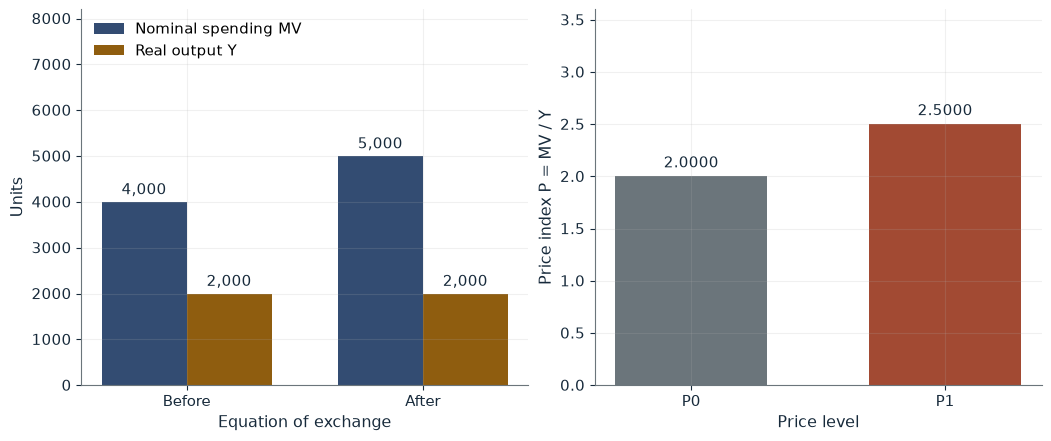

P0 = M0 V0 / Y0  2.0000
P1 = M1 V1 / Y1  2.5000
Change in P      25.00%
Change in money  25.00%

Worked steps:
  1. P0 = 1,000 x 4 / 2,000 = 4,000 / 2,000 = 2.0000
  2. P1 = 1,250 x 4.0 / 2,000 = 5,000 / 2,000 = 2.5000
  3. Change = (2.500000 - 2.0000) / 2.0000 = 25.00%

P0 = 1,000 x 4 / 2,000 = 2.0000. After the change, P1 = 1,250 x 4.0 / 2,000 = 2.5000, so the price index rises 25.00 percent. Money changed 25.00 percent; the price change differs from it whenever velocity or output moves.


In [2]:
show(quantity_picture(m1=1250, v1=4.0, y1=2000))

Change one input, `v1`, and hold the others at the book's values:

In [3]:
sweep(quantity_picture, 'v1', [3.2, 4.0], {'m1': 1250, 'y1': 2000}, ['P1 = M1 V1 / Y1', 'Change in P'])

v1 | P1 = M1 V1 / Y1 | Change in P
3.2 | 2.0000 | 0.00%
4.0 | 2.5000 | 25.00%


With velocity and output fixed, a 25 percent rise in money raises P by 25 percent, to 2.5. If velocity falls to 3.2 the index stays at 2; if output rises to 2,200 it rises only 13.64 percent.

## 2. Deflation and monetary contraction: falling prices raise real debt

Start from $M_0=500$, $V_0=4$, $Y_0=1{,}000$. A banking disruption cuts money to 450, velocity to 3.8 and output to 980:

$$P_1=\frac{450\times3.8}{980}\approx1.7449.$$

A borrower owes 200; the money stock that would restore $P=2$ is

$$M^*=\frac{P_0Y_1}{V_1}=\frac{2\times980}{3.8}\approx515.79.$$

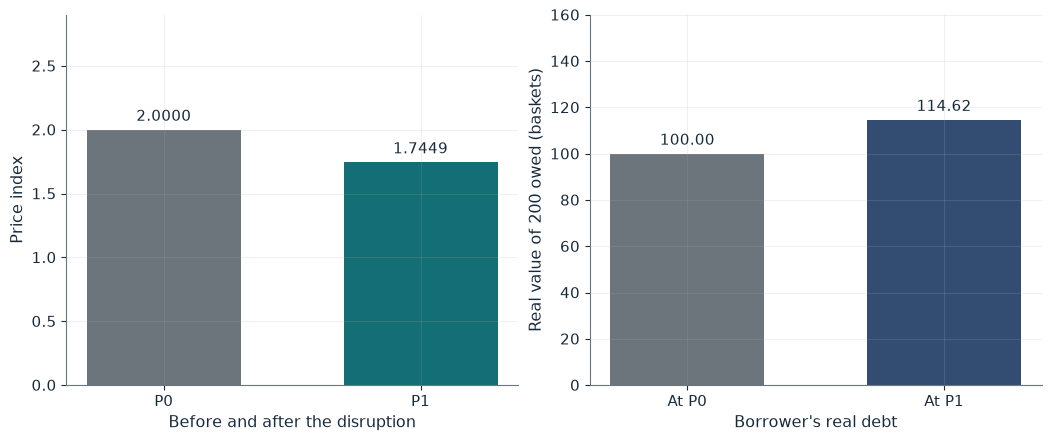

P1                         1.7449
Price change               -12.76%
Real debt before           100.00
Real debt after            114.62
Money that restores P = 2  515.79
Extra money needed         65.79

Worked steps:
  1. P0 = 500 x 4 / 1,000 = 2.0000
  2. P1 = 450 x 3.8 / 980 = 1.7449
  3. Change = (1.744898 - 2) / 2 = -12.76%
  4. Real debt = 200 / 1.744898 = 114.62 (was 100.00)
  5. M* = 2 x 980 / 3.8 = 515.79

P1 = 450 x 3.8 / 980 = 1,710 / 980 = 1.7449, so the price index falls 12.76 percent. The borrower's real debt rises, from 200 / 2 = 100.00 to 200 / 1.744898 = 114.62 baskets. Holding velocity at 3.8 and output at 980, the money stock that keeps P at 2 is 2 x 980 / 3.8 = 515.79, 65.79 more than 450.


In [4]:
show(deflation_picture(m1=450, v1=3.8))

Change one input, `v1`, and hold the others at the book's values:

In [5]:
sweep(deflation_picture, 'v1', [3.6, 3.8, 4.0, 4.2], {'m1': 450}, ['P1', 'Price change', 'Real debt after'])

v1 | P1 | Price change | Real debt after
3.6 | 1.6531 | -17.35% | 120.99
3.8 | 1.7449 | -12.76% | 114.62
4.0 | 1.8367 | -8.16% | 108.89
4.2 | 1.9286 | -3.57% | 103.70


Prices fall 12.76 percent, so the real debt rises from 100 to 114.62 baskets. Restoring P = 2 at the new velocity and output would take 65.79 more units of money, an accounting answer rather than a cure for insolvency.

## 3. Baumol-Tobin: how often to visit the bank

A business spends 24,000 dollars a year, each transfer costs 6 dollars and the interest rate is 4 percent. Annual cost is $C(n)=bn+iT/(2n)$, minimized at

$$n^*=\sqrt{\frac{0.04\times24{,}000}{2\times6}}=\sqrt{80}\approx8.944.$$

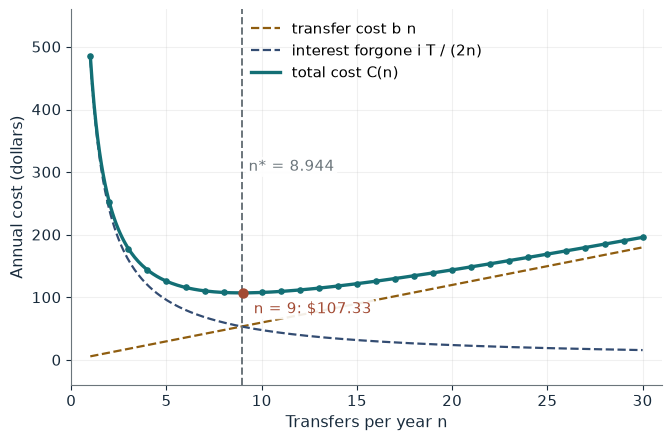

n* (continuous)                              8.944
Best whole n                                 9
C(best n)                                    $107.33
Average balance at best n                    $1,333.33
Average balance at n*                        $1,341.64
Cost at the whole numbers either side of n*  C(8) = $108.00 and C(9) = $107.33

Worked steps:
  1. n* = sqrt(0.04 x 24,000 / 12) = sqrt(80.00) = 8.944
  2. C(8) = 48 + 60.00 = $108.00
  3. C(9) = 54 + 53.33 = $107.33
  4. Average balance at n*: sqrt(6 x 24,000 / (2 x 0.04)) = $1,341.64

n* = sqrt(0.04 x 24,000 / (2 x 6)) = sqrt(80.00) = 8.944. Comparing the neighbouring whole numbers: C(8) = 6 x 8 + 0.04 x 24,000 / 16 = 48 + 60.00 = 108.00; C(9) = 6 x 9 + 0.04 x 24,000 / 18 = 54 + 53.33 = 107.33, so 9 transfers is the least-cost whole number. The average cash balance at n* is $1,341.64.


In [6]:
show(baumol_picture(i=0.04, b=6))

Change one input, `i`, and hold the others at the book's values:

In [7]:
sweep(baumol_picture, 'i', [0.02, 0.04, 0.09], {'b': 6}, ['n* (continuous)', 'Best whole n', 'C(best n)', 'Average balance at n*'])

i | n* (continuous) | Best whole n | C(best n) | Average balance at n*
0.02 | 6.325 | 6 | $76.00 | $1,897.37
0.04 | 8.944 | 9 | $107.33 | $1,341.64
0.09 | 13.416 | 13 | $161.08 | $894.43


Nine transfers cost \$107.33 a year against \$108 for eight or ten. At 9 percent interest n* rises to 13.416, only 1.5 times as many, because n* grows with the square root of i; the optimal average balance falls to \$894.43.

## 4. Seigniorage and the inflation tax

The public holds 10,000 units at $P_0=1$; the issuer adds 1,000 and prices rise to $P_1=1.10$. The exact erosion of existing balances is

$$\frac{10{,}000}{1}-\frac{10{,}000}{1.10}=10{,}000-9{,}090.91=909.09.$$

Seigniorage is $s=\frac{1{,}000}{1.10}=909.09$.

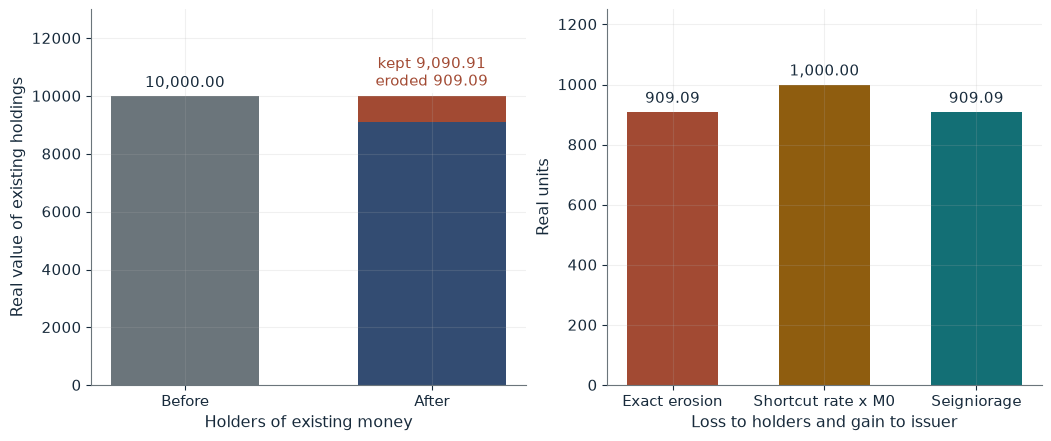

P1                                    1.1000
Inflation                             10.00%
Exact erosion                         909.09
Shortcut (rate x beginning balances)  1,000.00
Shortcut error                        90.91
Seigniorage                           909.09

Worked steps:
  1. P1 = (10,000 + 1,000) / 10,000 = 1.1000
  2. Exact erosion = 10,000 - 10,000 / 1.1000 = 10,000 - 9,090.91 = 909.09
  3. Same via final balances: 0.10 x 9,090.91 = 909.09
  4. Shortcut = 0.10 x 10,000 = 1,000.00, too high by 90.91
  5. Seigniorage s = 1,000 / 1.1000 = 909.09

With prices proportional to money, P1 = (10,000 + 1,000) / 10,000 = 1.1000, inflation of 10.00 percent. Exact erosion is 10,000 - 10,000 / 1.1000 = 10,000 - 9,090.91 = 909.09. The shortcut 0.10 x 10,000 = 1,000.00 is too high by 90.91. The issuer's real gain is 1,000 / 1.1000 = 909.09, equal to the holders' loss.


In [8]:
show(seigniorage_picture(issue=1000, holdings=10000))

Change one input, `issue`, and hold the others at the book's values:

In [9]:
sweep(seigniorage_picture, 'issue', [500, 1000, 2000], {'holdings': 10000}, ['Inflation', 'Exact erosion', 'Shortcut (rate x beginning balances)', 'Seigniorage'])

issue | Inflation | Exact erosion | Shortcut (rate x beginning balances) | Seigniorage
500 | 5.00% | 476.19 | 500.00 | 476.19
1000 | 10.00% | 909.09 | 1,000.00 | 909.09
2000 | 20.00% | 1,666.67 | 2,000.00 | 1,666.67


Holders lose 909.09 and the issuer gains 909.09. The shortcut 0.10 x 10,000 = 1,000 is 90.91 too high because it values the loss at the old price; the gap widens with larger issues.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

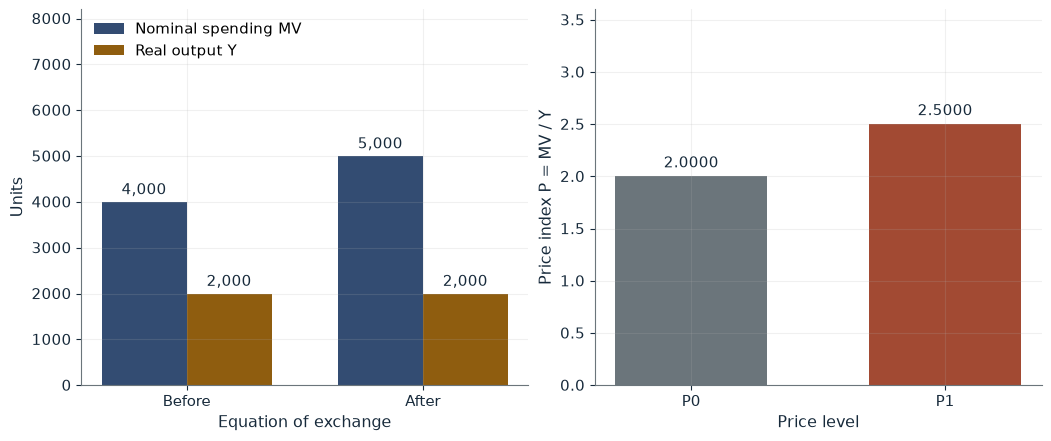

P0 = M0 V0 / Y0  2.0000
P1 = M1 V1 / Y1  2.5000
Change in P      25.00%
Change in money  25.00%

Worked steps:
  1. P0 = 1,000 x 4 / 2,000 = 4,000 / 2,000 = 2.0000
  2. P1 = 1,250 x 4.0 / 2,000 = 5,000 / 2,000 = 2.5000
  3. Change = (2.500000 - 2.0000) / 2.0000 = 25.00%

P0 = 1,000 x 4 / 2,000 = 2.0000. After the change, P1 = 1,250 x 4.0 / 2,000 = 2.5000, so the price index rises 25.00 percent. Money changed 25.00 percent; the price change differs from it whenever velocity or output moves.


In [10]:
show(quantity_picture(m1=1250, v1=4.0, y1=2000))

## Practice

**1.** With M1 = 1,250, V = 4 and output 2,200, what is the percent change in P?

<details><summary>Answer</summary>

P1 = 1,250 x 4 / 2,200 = 2.2727, and (2.2727 - 2) / 2 = 13.64 percent.

</details>

**2.** At i = 0.09, with T = 24,000 and b = 6, what are n* and the optimal average balance?

<details><summary>Answer</summary>

n* = sqrt(0.09 x 24,000 / 12) = sqrt(180) = 13.416; the average balance is sqrt(6 x 24,000 / 0.18) = \$894.43.

</details>

**3.** If 2,000 units are issued on holdings of 10,000 with proportional prices, what is the exact erosion?

<details><summary>Answer</summary>

P1 = 1.2, so 10,000 - 10,000 / 1.2 = 10,000 - 8,333.33 = 1,666.67, against the 2,000 shortcut.

</details>